In [45]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import itertools
import importlib
import Mi_functions
importlib.reload(Mi_functions)
from Mi_functions import bits_to_symbol_indices, gray_bitcount,\
    bold_d_and_w_ordered, bits_to_symbol_indices_binary, cm_batch_contribution_pair, estimate_cm_capacity_pair,\
    add_awgn_get_sigma, bicm_batch_contribution

#add_awgn, cm_batch_contribution, estimate_cm_capacity,

LOG2 = tf.math.log(tf.constant(2.0, tf.float32))
PI = tf.constant(np.pi, tf.float32)

In [46]:
@tf.function
def add_awgn(signal, ebno_db, bits_per_symbol):
    ebno_lin = tf.pow(10.0, ebno_db / 10.0)
    esno_lin = ebno_lin * tf.cast(bits_per_symbol, tf.float32)
    sigma = tf.sqrt(1.0 / (2*esno_lin))
    noise_r = tf.random.normal(tf.shape(signal), dtype=tf.float32)
    noise_i = tf.random.normal(tf.shape(signal), dtype=tf.float32)
    noise = tf.complex(noise_r, noise_i) * tf.cast(sigma, tf.complex64)
    return signal + noise

@tf.function
def add_phase_noise_and_awgn(signal, ebno_db, bits_per_symbol, phase_noise_var):
    ebno_db = tf.cast(ebno_db, tf.float32)
    bits_per_symbol = tf.cast(bits_per_symbol, tf.float32)
    phase_noise_var = tf.cast(phase_noise_var, tf.float32)

    # Phase noise: phi ~ N(0, phase_noise_var)
    phi = tf.random.normal(tf.shape(signal), stddev=tf.sqrt(phase_noise_var), dtype=tf.float32)
    phase_rot = tf.complex(tf.cos(phi), tf.sin(phi))
    signal_pn = signal * phase_rot

    # AWGN from Eb/N0
    ebno_lin = tf.pow(10.0, ebno_db / 10.0)
    esno_lin = ebno_lin * bits_per_symbol
    sigma = tf.sqrt(1.0 / (2.0 * esno_lin))

    noise_r = tf.random.normal(tf.shape(signal), dtype=tf.float32)
    noise_i = tf.random.normal(tf.shape(signal), dtype=tf.float32)
    noise = tf.complex(noise_r, noise_i) * tf.cast(sigma, tf.complex64)

    return signal_pn + noise

@tf.function
def wrap_to_pi(angle):
    return tf.math.floormod(angle + PI, 2.0 * PI) - PI

@tf.function
def sample_symbol_indices(B, px):
    logits = tf.math.log(tf.expand_dims(px, axis=0))   # [1,M]
    idx = tf.random.categorical(logits, B)             # [1,B]
    return tf.cast(tf.squeeze(idx, axis=0), tf.int32)  # [B]

@tf.function
def low_pn_approx_pdf(y, x, sigma_r, sigma_p):

    y = tf.cast(y, tf.complex64)
    x = tf.cast(x, tf.complex64)

    r = tf.abs(y)
    theta = tf.math.angle(y)

    l = tf.abs(x)
    alpha = tf.math.angle(x)
    alpha_c = tf.complex(alpha,0.0)

    r = tf.cast(r, tf.float32)
    l = tf.cast(l, tf.float32)

    sigma_r = tf.cast(sigma_r, tf.float32)
    sigma_p = tf.cast(sigma_p, tf.float32)

    complx_number = y*tf.exp(-1j*alpha_c)

    log_norm = -tf.math.log(2.0 * PI * sigma_r * tf.sqrt((l**2)*sigma_p**2 + sigma_r**2))

    log_real = -(tf.abs(tf.math.real(complx_number) - l) ** 2) / (2.0 * sigma_r ** 2)
    log_imag = -(tf.math.imag(complx_number) ** 2) / (2.0 * ((l**2)*sigma_p**2 + sigma_r**2))

    return log_norm + log_real + log_imag

@tf.function
def log_polar_approx_pdf(y, x, sigma_r, sigma_p, eps=1e-8):

    y = tf.cast(y, tf.complex64)
    x = tf.cast(x, tf.complex64)

    r = tf.abs(y)
    theta = tf.math.angle(y)

    l = tf.abs(x)
    alpha = tf.math.angle(x)

    dtheta = wrap_to_pi(theta - alpha)

    r = tf.cast(r, tf.float32)
    l = tf.cast(l, tf.float32)
    dtheta = tf.cast(dtheta, tf.float32)

    sigma_r = tf.cast(sigma_r, tf.float32)
    sigma_p = tf.cast(sigma_p, tf.float32)
    eps = tf.cast(eps, tf.float32)

    log_norm = -tf.math.log(2.0 * PI * sigma_r * tf.sqrt((l**2)*sigma_p**2 + sigma_r**2))
    # log_jac = -tf.math.log(tf.maximum(r, eps))
    log_radial = -(tf.abs(r - l) ** 2) / (2.0 * sigma_r ** 2)
    log_angular = -(dtheta ** 2) / (2.0 * (sigma_p**2 + (1/(l**2))*sigma_r**2))

    return log_norm + log_radial + log_angular

@tf.function
def cm_batch_contribution_low_pn(y, x_sent, sigma_r, sigma_p, m, symbols, px):

    y = tf.cast(y, tf.complex64)
    x_sent = tf.cast(x_sent, tf.complex64)
    symbols = tf.cast(symbols, tf.complex64)
    y_exp = tf.expand_dims(y, axis=1)          # [B,1]
    sym_exp = tf.expand_dims(symbols, axis=0)  # [1,M]

    log_px = tf.math.log(px)                           # [M]

    logp_all = low_pn_approx_pdf(y_exp, sym_exp, sigma_r, sigma_p)   # [B,M]

    logp_all = logp_all + log_px[tf.newaxis, :]
    log_sumprob = tf.reduce_logsumexp(logp_all, axis=1)                 # [B]
    logp_sent = low_pn_approx_pdf(y, x_sent, sigma_r, sigma_p)       # [B]
    # vals = tf.cast(m, tf.float32) - (log_sumprob - logp_sent) / LOG2
    vals = (logp_sent - log_sumprob) / tf.math.log(2.0)      # [B]
    return tf.reduce_sum(vals)

@tf.function
def cm_batch_contribution_polar(y, x_sent, sigma_r, sigma_p, m, symbols, px):

    y = tf.cast(y, tf.complex64)
    x_sent = tf.cast(x_sent, tf.complex64)
    symbols = tf.cast(symbols, tf.complex64)
    y_exp = tf.expand_dims(y, axis=1)          # [B,1]
    sym_exp = tf.expand_dims(symbols, axis=0)  # [1,M]

    log_px = tf.math.log(px)                           # [M]

    logp_all = log_polar_approx_pdf(y_exp, sym_exp, sigma_r, sigma_p)   # [B,M]
    logp_all = logp_all + log_px[tf.newaxis, :]
    log_sumprob = tf.reduce_logsumexp(logp_all, axis=1)                 # [B]
    logp_sent = log_polar_approx_pdf(y, x_sent, sigma_r, sigma_p)       # [B]
    vals = (logp_sent - log_sumprob) / tf.math.log(2.0)                 # [B]
    # vals = tf.cast(m, tf.float32) - (log_sumprob - logp_sent) / LOG2
    return tf.reduce_sum(vals)

@tf.function
def log_p_y_given_x_mc(y, x, noise_var, phase_noise_var, n_phi_mc):
    y = tf.cast(y, tf.complex64)                         # [B] or [B,M]
    x = tf.cast(x, tf.complex64)                         # same shape as y
    noise_var = tf.cast(2*noise_var, tf.float32)
    phase_noise_var = tf.cast(phase_noise_var, tf.float32)

    shape_y = tf.shape(y)
    phi_shape = tf.concat([[n_phi_mc], shape_y], axis=0)   # [K,...]

    phi = tf.random.normal(phi_shape,
                           stddev=tf.sqrt(phase_noise_var),
                           dtype=tf.float32)               # [K,...]
    rot = tf.complex(tf.cos(phi), tf.sin(phi))             # [K,...]

    x_exp = tf.expand_dims(x, axis=0)                      # [1,...]
    y_exp = tf.expand_dims(y, axis=0)                      # [1,...]

    mu = x_exp * rot                                       # [K,...]
    d2 = tf.abs(y_exp - mu) ** 2                           # [K,...]
    d2 = tf.cast(d2, tf.float32)

    # CN(mu, noise_var): p(y|x,phi)=1/(pi*noise_var) exp(-|y-mu|^2/noise_var)
    log_pdf_given_phi = -tf.math.log(np.pi * noise_var) - d2 / noise_var   # [K,...]

    # log E_phi[p(y|x,phi)] = logsumexp(log p(y|x,phi_k)) - log(K)
    return tf.reduce_logsumexp(log_pdf_given_phi, axis=0) - tf.math.log(tf.cast(n_phi_mc, tf.float32))

@tf.function
def cm_batch_contribution_phase_exact(y, x_sent, noise_var, phase_noise_var, m, symbols, n_phi_mc, px):
    y = tf.cast(y, tf.complex64)                 # [B]
    x_sent = tf.cast(x_sent, tf.complex64)       # [B]
    symbols = tf.cast(symbols, tf.complex64)     # [M]

    log_px = tf.math.log(px)                           # [M]

    y_exp = tf.expand_dims(y, axis=1)            # [B,1]
    sym_exp = tf.expand_dims(symbols, axis=0)    # [1,M]
    sym_exp = tf.broadcast_to(
    tf.expand_dims(symbols, 0),
    [tf.shape(y)[0], tf.shape(symbols)[0]]
    ) #[B,M]

    y_grid = tf.broadcast_to(y_exp, tf.shape(sym_exp))     # [B,M]

    logp_all = log_p_y_given_x_mc(
        y_grid,
        sym_exp,
        noise_var,
        phase_noise_var,
        n_phi_mc
    )                                              # [B,M]

    logp_sent = log_p_y_given_x_mc(
        y,
        x_sent,
        noise_var,
        phase_noise_var,
        n_phi_mc
    )                                              # [B]

    # Uniform input: I = m + E[ log2 p(y|x) - log2 sum_x' p(y|x') ]
    logp_all = logp_all + log_px[tf.newaxis, :]
    log_sumprob = tf.reduce_logsumexp(logp_all, axis=1)    # [B]
    # vals = tf.cast(m, tf.float32) + (logp_sent - log_sumprob) / LOG2
    vals = (logp_sent - log_sumprob) / tf.math.log(2.0)
    # print('vals :',vals[:20].numpy())
    return tf.reduce_sum(vals)

@tf.function
def mi_batch_contribution(y, x_idx, noise_var, symbols, px):
    # y: [B], x_idx: [B], symbols: [M], px: [M]

    y_exp = tf.expand_dims(y, axis=1)                  # [B,1]
    sym_exp = tf.expand_dims(symbols, axis=0)          # [1,M]

    d2_all = tf.abs(y_exp - sym_exp) ** 2              # [B,M]
    exponents_all = -tf.cast(d2_all, tf.float32) / (2.0 * noise_var)

    # log p(y|x_j) up to additive Gaussian constant
    # constant cancels in numerator/denominator ratio
    log_px = tf.math.log(px)                           # [M]
    log_terms = exponents_all + log_px[tf.newaxis, :]  # [B,M]

    log_den = tf.reduce_logsumexp(log_terms, axis=1)   # [B]

    x_sent = tf.gather(symbols, x_idx)
    d2_sent = tf.abs(y - x_sent) ** 2
    log_num = -tf.cast(d2_sent, tf.float32) / (2.0 * noise_var)  # [B]

    vals = (log_num - log_den) / tf.math.log(2.0)      # [B]
    return tf.reduce_sum(vals)

def estimate_mi_nonuniform(esno_db_vec, n_samples, batch_size, symbols, px):
    M = len(symbols.numpy())
    mi = np.zeros(len(esno_db_vec), dtype=np.float32)
    shannoncap = np.zeros(len(esno_db_vec), dtype=np.float32)

    num_batches = int(np.ceil(n_samples / batch_size))
    px_tf = tf.constant(px, dtype=tf.float32)

    for n, esno_db in enumerate(esno_db_vec):
        esno_lin = 10 ** (esno_db / 10.0)
        noise_var = np.float32(1.0 / (2.0 * esno_lin))
        shannoncap[n] = 0.5 * np.log2(1.0 + 2.0 * esno_lin)

        total = 0.0
        done = 0

        for _ in range(num_batches):
            B = min(batch_size, n_samples - done)
            if B <= 0:
                break

            idx = sample_symbol_indices(B, px_tf)
            x_sent = tf.gather(symbols, idx)
            y = add_awgn_esno(x_sent, tf.constant(esno_db, tf.float32))

            batch_sum = mi_batch_contribution(
                y,
                idx,
                tf.constant(noise_var, dtype=tf.float32),
                symbols,
                px_tf
            )

            total += float(batch_sum.numpy())
            done += B

        mi[n] = total / n_samples
        print(f"Es/No = {esno_db:.1f} dB, MI = {mi[n]:.6f}")

    return mi, shannoncap


In [47]:
def estimate_cm_capacity(esno_db_vec, n_samples, batch_size, m, symbols, px, pn_var, condition):
    ccCap = np.zeros(len(esno_db_vec), dtype=np.float32)
    shannoncap = np.zeros(len(esno_db_vec), dtype=np.float32)
    px_tf = tf.constant(px, dtype=tf.float32)
    num_batches = int(np.ceil(n_samples / batch_size))

    for n, esno_db in enumerate(esno_db_vec):
        ebno_db = esno_db - 10 * np.log10(m)
        esno_lin = 10 ** (esno_db / 10.0)
        noise_var = np.float32(1.0 / (2*esno_lin))
        if condition == 'exact':
            print('ebno_db :',ebno_db)
        shannoncap[n] = np.log2(1.0 + esno_lin)

        total = 0.0
        done = 0

        for _ in range(num_batches):
            B = min(batch_size, n_samples - done)
            if B <= 0:
                break

            idx = sample_symbol_indices(B, px_tf)
            x_sent = tf.gather(symbols, idx)

            if condition == 'awgn':
                y = add_awgn(x_sent, tf.constant(ebno_db, tf.float32), m)   # [B]
            else:
                y = add_phase_noise_and_awgn(x_sent, tf.constant(ebno_db, tf.float32), m, pn_var)   # [B]

            if condition == 'awgn':
                batch_sum = mi_batch_contribution(
                    y,
                    idx,
                    tf.constant(noise_var, dtype=tf.float32),
                    symbols,
                    px_tf
                )
            elif condition == 'lowpn':
                batch_sum = cm_batch_contribution_low_pn(
                    y,
                    x_sent,
                    tf.sqrt(tf.maximum(tf.cast(noise_var, tf.float32), 0)),
                    tf.constant(tf.sqrt(pn_var), dtype=tf.float32),
                    m,
                    symbols,
                    px_tf
                )
            elif condition == 'highsnr':
                batch_sum = cm_batch_contribution_polar(
                    y,
                    x_sent,
                    tf.constant(tf.sqrt(noise_var), dtype=tf.float32),
                    tf.constant(tf.sqrt(pn_var), dtype=tf.float32),
                    m,
                    symbols,
                    px_tf
                )
            elif condition == 'exact':
                batch_sum = cm_batch_contribution_phase_exact(
                    y=y,
                    x_sent=x_sent,
                    noise_var=tf.maximum(tf.cast(noise_var, tf.float32), 0),
                    phase_noise_var=tf.constant(pn_var, tf.float32),
                    m=m,
                    symbols=symbols,
                    n_phi_mc=tf.constant(1024, tf.int32),
                    px=px_tf
                )

            total += float(batch_sum.numpy())
            done += B
            if condition == 'exact':
                print(done,'/',n_samples,' Complete')

        ccCap[n] = total / n_samples
        # print(f"Es/No = {esno_db:.1f} dB, Noise var = {noise_var:.6f}, CM capacity = {ccCap[n]:.6f}, -10*np.log10(ccCap) = {-10*np.log10(ccCap[n]):.6f}")
    print('done')
    return ccCap, shannoncap

In [48]:
data = np.load("snr_13_papr_7.2.npz")
symbols_np = data["constellation_points"]
px = np.squeeze(data["constellation_probabilities"])

In [5]:
# # labels = ['000','001','011','010','110','111','101','100']  # BRGC order

# # labels = ['000','101','010','111','011','110','001','100']  # badlabeling

# labels = ['000','110','100','010','001','111','101','011']  # Graylike labeling

# q2, q1, q0 = 0.5, 0.5, 0.2

# bits = np.array([[int(c) for c in s] for s in labels], dtype=float)
# q = np.array([q2, q1, q0])

# px = np.prod(np.where(bits == 1, q, 1 - q), axis=1)

print(px)
print(px.sum())

[0.02668766 0.00456234 0.02668766 0.00456234 0.02668766 0.00456234
 0.02668766 0.00456234 0.02668766 0.00456234 0.02668766 0.00456234
 0.02668766 0.00456234 0.02668766 0.00456234 0.02668766 0.00456234
 0.02668766 0.00456234 0.02668766 0.00456234 0.02668766 0.00456234
 0.02668766 0.00456234 0.02668766 0.00456234 0.02668766 0.00456234
 0.02668766 0.00456234 0.02668766 0.00456234 0.02668766 0.00456234
 0.02668766 0.00456234 0.02668766 0.00456234 0.02668766 0.00456234
 0.02668766 0.00456234 0.02668766 0.00456234 0.02668766 0.00456234
 0.02668766 0.00456234 0.02668766 0.00456234 0.02668766 0.00456234
 0.02668766 0.00456234 0.02668766 0.00456234 0.02668766 0.00456234
 0.02668766 0.00456234 0.02668766 0.00456234]
1.0000001


In [43]:
# symbols_np = np.array([-1-1j, 1+1j, -1+1j, 1-1j, -2-2j, 2+2j, -2+2j, 2-2j], dtype=np.complex64)
# labels = ['100','000','010','110','011','111','101','001']  # Much worse labeling

In [ ]:

# labels = ['000','100','110','010','001','101','111','011']  # Random 2

In [49]:
# Use GPU if available
print("GPUs:", tf.config.list_physical_devices('GPU'))

# =========================
# Parameters
# =========================

EsNoVec = np.arange(-6, 35, 1, dtype=np.float32)   # Es/No in dB
N_bicm = 10_000_0
m = 6
M = 2 ** m
batch_size = 500000  # tune based on GPU memory
EbNoVec = EsNoVec - 10 * np.log10(m)

# symbols_np = np.array([-7+0j, -5+0j, -3+0j, -1+0j, 1+0j ,3+0j, 5+0j, 7+0j], dtype=np.complex64)
# symbols_np = np.array([-1-1j, 1+1j, -1+1j, 1-1j, -2-2j, 2+2j, -2+2j, 2-2j], dtype=np.complex64)
symbols_np = symbols_np/np.sqrt(np.mean(np.abs(symbols_np)**2, axis=0, keepdims=True))

def normalize_symbols_for_px(symbols_np, px):
    avg_e = np.sum(px * (np.abs(symbols_np) ** 2))
    return symbols_np / np.sqrt(avg_e)

if symbols_np.size != M:
    raise ValueError("Please paste the exact constellation points from MATLAB into symbols_np")

px /= px.sum()

symbols_np = normalize_symbols_for_px(symbols_np, px)
symbols = tf.constant(symbols_np, dtype=tf.complex64)

GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [50]:
pn_var = 0.0032
ccCap_awgn, shannoncap = estimate_cm_capacity(EsNoVec, N_bicm, batch_size, m, symbols, px, pn_var, 'awgn')
ccCap_lowpn, shannoncap = estimate_cm_capacity(EsNoVec, N_bicm, batch_size, m, symbols, px, pn_var, 'lowpn')
ccCap_highsnr, shannoncap = estimate_cm_capacity(EsNoVec, N_bicm, batch_size, m,  symbols, px, pn_var, 'highsnr')
ccCap_exact, shannoncap = estimate_cm_capacity(EsNoVec, N_bicm, int(batch_size/200), m, symbols, px, pn_var, 'exact')


done
done
done
ebno_db : -13.781512503836437
2500 / 100000  Complete
5000 / 100000  Complete
7500 / 100000  Complete
10000 / 100000  Complete
12500 / 100000  Complete
15000 / 100000  Complete
17500 / 100000  Complete
20000 / 100000  Complete
22500 / 100000  Complete
25000 / 100000  Complete
27500 / 100000  Complete
30000 / 100000  Complete
32500 / 100000  Complete
35000 / 100000  Complete
37500 / 100000  Complete
40000 / 100000  Complete
42500 / 100000  Complete
45000 / 100000  Complete
47500 / 100000  Complete
50000 / 100000  Complete
52500 / 100000  Complete
55000 / 100000  Complete
57500 / 100000  Complete
60000 / 100000  Complete
62500 / 100000  Complete
65000 / 100000  Complete
67500 / 100000  Complete
70000 / 100000  Complete
72500 / 100000  Complete
75000 / 100000  Complete
77500 / 100000  Complete
80000 / 100000  Complete
82500 / 100000  Complete
85000 / 100000  Complete
87500 / 100000  Complete
90000 / 100000  Complete
92500 / 100000  Complete
95000 / 100000  Complete
97500 / 

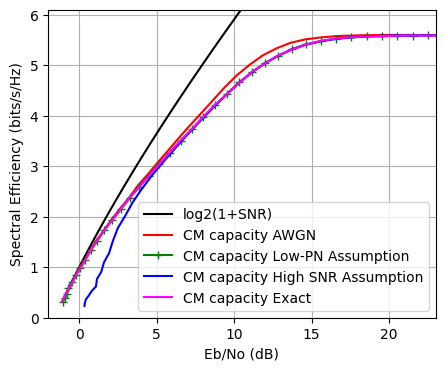

In [11]:
plt.figure(figsize=(5, 4))
plt.plot(EsNoVec-10*np.log10(shannoncap), shannoncap, '-', label='log2(1+SNR)', color='black') #-10*np.log10(shannoncap)
plt.plot(EsNoVec-10*np.log10(ccCap_awgn), ccCap_awgn, '-', label='CM capacity AWGN', color='red') #-10*np.log10(ccCap)
plt.plot(EsNoVec-10*np.log10(ccCap_lowpn), ccCap_lowpn, '-+', label='CM capacity Low-PN Assumption', color='green') #-10*np.log10(ccCap)
plt.plot(EsNoVec-10*np.log10(ccCap_highsnr), ccCap_highsnr, '-', label='CM capacity High SNR Assumption', color='blue') #-10*np.log10(ccCap)
plt.plot(EsNoVec-10*np.log10(ccCap_exact), ccCap_exact, '-', label='CM capacity Exact', color='magenta') #-10*np.log10(ccCap)
# plt.title(f"Phase noise var = {pn_var:.6f} CM capacity plot")
plt.grid(True)
plt.ylim([0, 6.1])
plt.xlim([-2, 23])
plt.xlabel('Eb/No (dB)')
plt.ylabel('Spectral Efficiency (bits/s/Hz)')
plt.legend()
plt.savefig("cm_capacity_plot.png", dpi=200, bbox_inches="tight")

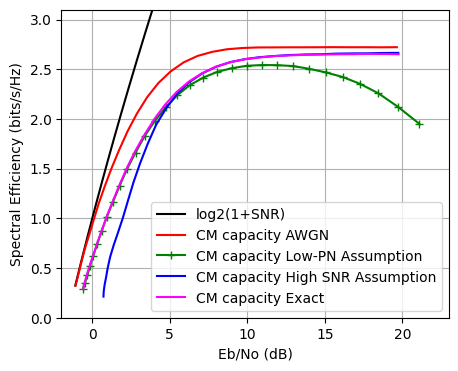

In [20]:
px_tf = tf.constant(px, dtype=tf.float32)
esno_db = 20.0
ebno_db = esno_db - 10 * np.log10(m)
esno_lin = 10 ** (esno_db / 10.0)
noise_var = np.float32(1.0 / (2*esno_lin))

B = 500000
idx = sample_symbol_indices(B, px_tf)
x_sent = tf.gather(symbols, idx)
y_for_plot = add_phase_noise_and_awgn(x_sent, tf.constant(ebno_db, tf.float32), m, pn_var)   # [B]

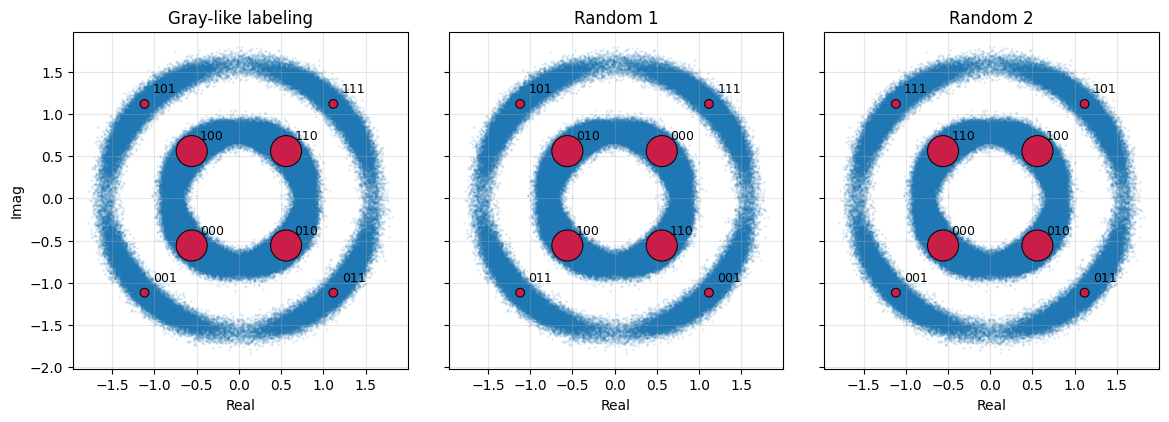

In [77]:
x_np = y_for_plot.numpy()
sym = np.asarray(symbols_np)

label_sets = [
    (['000','110','100','010','001','111','101','011'], 'Gray-like labeling'),
    (['100','000','010','110','011','111','101','001'], 'Random 1'),
    (['000','100','110','010','001','101','111','011'], 'Random 2'),
]

probability = np.array([0.2, 0.2, 0.2, 0.2, 0.05, 0.05, 0.05, 0.05])

s_min, s_max = 40, 500
p_norm = (probability - probability.min()) / (probability.max() - probability.min() + 1e-12)
sizes = s_min + p_norm * (s_max - s_min)

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True)

for ax, (labels, title) in zip(axes, label_sets):
    ax.scatter(x_np.real, x_np.imag, s=1, alpha=0.1)
    ax.scatter(
        sym.real, sym.imag,
        s=sizes, c='crimson',
        edgecolors='black', linewidths=0.8,
        alpha=0.9, zorder=3
    )

    for x, y, lab in zip(sym.real, sym.imag, labels):
        ax.annotate(
            lab, xy=(x, y), xytext=(6, 6),
            textcoords='offset points',
            fontsize=9, ha='left', va='bottom',
            zorder=4
        )

    ax.set_title(title)
    ax.set_xlabel("Real")
    ax.grid(True, alpha=0.3)
    ax.set_aspect("equal", adjustable="box")

axes[0].set_ylabel("Imag")
plt.tight_layout()
plt.savefig("three_labelings.png", dpi=200, bbox_inches="tight")
plt.show()


### MI pairwise averaging

In [6]:
@tf.function
def sample_pair_indices(bits, idx_pair, q_pair):
    # bits: [B,1] in {0,1}
    # q_pair: [2] effective probabilities summing to 1
    u = tf.random.uniform(tf.shape(bits), dtype=tf.float64)
    bits_eff = tf.cast(u < q_pair[1], tf.int32)  # 1 with prob q1, else 0
    idx = tf.gather(idx_pair, bits_eff)
    return idx, bits_eff

@tf.function
def bits_to_symbol_indices_binary(bits, idx_pair):
    # bits shape: [B, 1], 0 or 1
    # idx_pair: [2] containing the two symbol indices to use
    idx = tf.gather(idx_pair, bits)  # [B]
    return idx

@tf.function
def cm_batch_contribution_pair_polar(y, x_sent, sigma_r, sigma_p, idx_pair, symbols):

    sym_pair = tf.gather(symbols, idx_pair)    # [2]
    sym_exp = tf.expand_dims(sym_pair, axis=0) # [1,2]
    y_exp = y

    logp_all = log_polar_approx_pdf(y_exp, sym_exp, sigma_r, sigma_p)   # [B,2]
    log_sumprob = tf.expand_dims(tf.reduce_logsumexp(logp_all, axis=1),axis=1)                 # [B]
    logp_sent = log_polar_approx_pdf(y, x_sent, sigma_r, sigma_p)       # [B]

    vals = tf.cast(1, tf.float32) - (log_sumprob - logp_sent) / LOG2
    return tf.reduce_sum(vals)

@tf.function
def cm_batch_contribution_pair_low_pn(y, x_sent, sigma_r, sigma_p, idx_pair, symbols):

    sym_pair = tf.gather(symbols, idx_pair)    # [2]
    sym_exp = tf.expand_dims(sym_pair, axis=0) # [1,2]
    y_exp = y

    logp_all = low_pn_approx_pdf(y_exp, sym_exp, sigma_r, sigma_p)   # [B,2]
    log_sumprob = tf.expand_dims(tf.reduce_logsumexp(logp_all, axis=1),axis=1)                 # [B]
    logp_sent = low_pn_approx_pdf(y, x_sent, sigma_r, sigma_p)       # [B]

    vals = tf.cast(1, tf.float32) - (log_sumprob - logp_sent) / LOG2
    return tf.reduce_sum(vals)



@tf.function
def cm_batch_contribution_pair_exact(y, x_sent, noise_var, phase_noise_var, idx_pair, symbols, q_pair):

    x_sent = tf.squeeze(x_sent)
    sym_pair = tf.gather(symbols, idx_pair)    # [2]
    # print('sym_pair.shape:', sym_pair.shape)
    sym_exp = tf.expand_dims(sym_pair, axis=0) # [1,2]
    # print('sym_exp.shape:', sym_exp.shape)
    # print('x_sent.shape:', x_sent.shape)
    y_exp = y

    sym_exp = tf.broadcast_to(
    tf.expand_dims(sym_pair, 0),
    [tf.shape(y_exp)[0], tf.shape(sym_pair)[0]]
    ) #[2,M]
    # print('sym_exp.shape:', sym_exp.shape)
    y_grid = tf.broadcast_to(y_exp, tf.shape(sym_exp))     # [B,2]
    # print('y_grid.shape:', y_grid.shape)
    logp_all = log_p_y_given_x_mc(
        y_grid,
        sym_exp,
        noise_var,
        phase_noise_var,
        1024
    )                                              # [B,M]

    log_num = log_p_y_given_x_mc(
        tf.squeeze(y),
        x_sent,
        noise_var,
        phase_noise_var,
        1024
    )                                              # [B]

    log_q = tf.math.log(tf.cast(q_pair, tf.float32))             # [2]
    logp_all = logp_all + log_q[tf.newaxis, :]                  # [B,2]

    log_den = tf.reduce_logsumexp(logp_all, axis=1)          # [B]
    vals = (log_num - log_den) / tf.math.log(2.0)                # [B]
    return tf.reduce_sum(vals)

@tf.function
def cm_batch_contribution_pair(y, x_sent, noise_var, idx_pair, symbols, q_pair):

    y_exp = y          # [B,1]
    sym_pair = tf.gather(symbols, idx_pair)    # [2]
    sym_exp = tf.expand_dims(sym_pair, axis=0) # [1,2]
    d2_all = tf.abs(y_exp - sym_exp) ** 2      # [B,2]

    exponents_all = -tf.cast(d2_all, tf.float32) / (2.0 * noise_var)
    log_q = tf.math.log(tf.cast(q_pair, tf.float32))             # [2]
    log_terms = exponents_all + log_q[tf.newaxis, :]             # [B,2]

    log_den = tf.reduce_logsumexp(log_terms, axis=1)             # [B]
    d2_sent = tf.squeeze(tf.abs(y - x_sent)) ** 2
    log_num = -tf.cast(d2_sent, tf.float32) / (2.0 * noise_var)  # [B]
    vals = (log_num - log_den) / tf.math.log(2.0)                # [B]

    return tf.reduce_sum(vals)


def estimate_cm_capacity_pair_pn(esno_db_vec, n_samples, batch_size, idx_pair, symbols, pn_var, condition):
    """
    idx_pair: [2] tensor/array containing the two symbol indices to transmit
    """
    ccCap = np.zeros(len(esno_db_vec), dtype=np.float32)
    shannoncap = np.zeros(len(esno_db_vec), dtype=np.float32)
    num_batches = int(np.ceil(n_samples / batch_size))
    
    idx_pair_tf = tf.constant(idx_pair, dtype=tf.int32)

    p_pair = tf.gather(px, idx_pair) 
    q_pair_tf = p_pair / tf.reduce_sum(p_pair)

    for n, esno_db in enumerate(esno_db_vec):
        ebno_db = esno_db - 10 * np.log10(1)  # m=1 for binary
        esno_lin = 10 ** (esno_db / 10.0)
        noise_var = np.float32(1.0 / (2*esno_lin))
        shannoncap[n] = 0.5*np.log2(1.0 + 2*esno_lin)  # Shannon for binary

        total = 0.0
        done = 0

        for _ in range(num_batches):
            B = min(batch_size, n_samples - done)
            if B <= 0:
                break

            bits = tf.random.uniform((B, 1), minval=0, maxval=2, dtype=tf.int32)
            idx, bits_eff = sample_pair_indices(bits, idx_pair_tf, q_pair_tf)
            x_sent = tf.gather(symbols, idx)
            
            if condition == 'awgn':
                y = add_awgn(x_sent, tf.constant(ebno_db, tf.float32), 1)   # [B]
            else:
                y = add_phase_noise_and_awgn(x_sent, tf.constant(ebno_db, tf.float32), 1, pn_var)   # [B]

            if condition == 'awgn':
                batch_sum = cm_batch_contribution_pair(
                    y,
                    x_sent,
                    tf.constant(noise_var, dtype=tf.float32),
                    idx_pair_tf,
                    symbols,
                    q_pair_tf
                )
            elif condition == 'exact':
                batch_sum = cm_batch_contribution_pair_exact(
                    y,
                    x_sent,
                    tf.constant(noise_var, dtype=tf.float32),
                    tf.constant(pn_var, dtype=tf.float32),
                    idx_pair_tf,
                    symbols,
                    q_pair_tf
                )
            elif condition == 'lowpn':
                batch_sum = cm_batch_contribution_pair_low_pn(
                    y,
                    x_sent,
                    tf.constant(tf.sqrt(noise_var), dtype=tf.float32),
                    tf.constant(tf.sqrt(pn_var), dtype=tf.float32),
                    idx_pair_tf,
                    symbols
                )
            elif condition == 'highsnr':
                batch_sum = cm_batch_contribution_pair_polar(
                    y,
                    x_sent,
                    tf.constant(tf.sqrt(noise_var), dtype=tf.float32),
                    tf.constant(tf.sqrt(pn_var), dtype=tf.float32),
                    idx_pair_tf,
                    symbols
                )
                
            total += float(batch_sum.numpy())
            done += B

        ccCap[n] = total / n_samples
        print(f"Es/No = {esno_db:.1f} dB, Pair MI = {ccCap[n]:.6f}")

    return ccCap, shannoncap

In [9]:
# symbols_np = np.array([-1-1j, 1+1j, -1+1j, 1-1j, -2-2j, 2+2j, -2+2j, 2-2j], dtype=np.complex64)
# symbols_np = symbols_np/np.sqrt(np.mean(np.abs(symbols_np)**2, axis=0, keepdims=True))

def normalize_symbols_for_px(symbols_np, px):
    avg_e = np.sum(px * (np.abs(symbols_np) ** 2))
    return symbols_np / np.sqrt(avg_e)

px /= px.sum()

symbols_np = normalize_symbols_for_px(symbols_np, px)
symbols = tf.constant(symbols_np, dtype=tf.complex64)

all_pairs = list(itertools.combinations(range(M), 2))

In [16]:
px.dtype

dtype('float32')

In [17]:
px = px.astype(np.float64)

In [18]:
len(all_pairs)

2016

In [ ]:

# all_pairs = [(0,1)]
results_exact = {}
# pn_var = 0.1

for idx_pair in all_pairs:
    idx_pair_tf = tf.constant(list(idx_pair), dtype=tf.int32)
    ccCap_pair, shannon = estimate_cm_capacity_pair_pn(
        EsNoVec, N_bicm, int(batch_size/10), idx_pair_tf, symbols, pn_var,'exact'
    )
    results_exact[idx_pair] = {
        "ccCap": ccCap_pair,
        "shannon": shannon
    }
    print(f"Done pair {idx_pair}")

# Fix the symbol order and change label array
# symbols_np = np.array([-7+0j, -5+0j, -3+0j, -1+0j, 1+0j ,3+0j, 5+0j, 7+0j], dtype=np.complex64)
# symbols_np = np.array([-1-1j, 1+1j, -1+1j, 1-1j, -2-2j, 2+2j, -2+2j, 2-2j], dtype=np.complex64)
# symbols_np = symbols_np/np.sqrt(np.mean(np.abs(symbols_np)**2, axis=0, keepdims=True))
# symbols = tf.constant(symbols_np, dtype=tf.complex64)



In [68]:
data = np.load("results_exact.npz")

# Reconstruct results_exact if needed
results_exact_loaded = {}
for i, j in all_pairs:
    results_exact_loaded[(i, j)] = {
        "ccCap": data[f"ccCap_{i}_{j}"],
        "shannon": data[f"shannon_{i}_{j}"],
    }

# Function to compute Hamming distance between two bit patterns
def hamming_distance(bits_a, bits_b):
    return np.sum(bits_a != bits_b)

6

In [13]:
labels = [f"{i:0{m}b}" for i in range(2**m)] # Numerical order

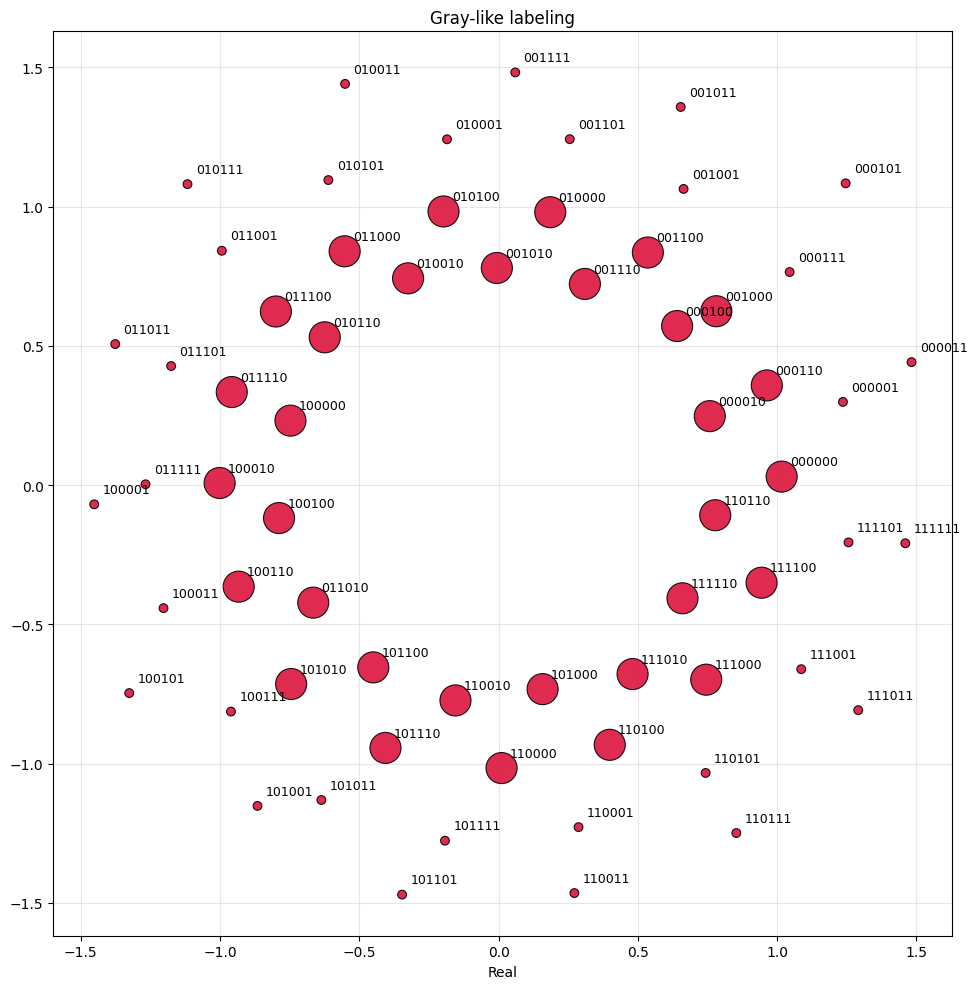

In [29]:
sym = np.asarray(symbols_np)

label_sets = [
    (labels, 'Gray-like labeling')
]

# probability = np.array([0.2, 0.2, 0.2, 0.2, 0.05, 0.05, 0.05, 0.05])
probability = px

s_min, s_max = 40, 500
p_norm = (probability - probability.min()) / (probability.max() - probability.min() + 1e-12)
sizes = s_min + p_norm * (s_max - s_min)

fig, ax = plt.subplots(1, 1, figsize=(10, 10), sharex=True, sharey=True)


# ax.scatter(x_np.real, x_np.imag, s=1, alpha=0.1)
ax.scatter(
    sym.real, sym.imag,
    s=sizes, c='crimson',
    edgecolors='black', linewidths=0.8,
    alpha=0.9, zorder=3
)

for x, y, lab in zip(sym.real, sym.imag, labels):
    ax.annotate(
        lab, xy=(x, y), xytext=(6, 6),
        textcoords='offset points',
        fontsize=9, ha='left', va='bottom',
        zorder=4
    )

ax.set_title(title)
ax.set_xlabel("Real")
ax.grid(True, alpha=0.3)
ax.set_aspect("equal", adjustable="box")

# axes[0].set_ylabel("Imag")
plt.tight_layout()
# plt.savefig("three_labelings.png", dpi=200, bbox_inches="tight")
plt.show()

In [33]:

q = np.array([0.5, 0.5, 0.5, 0.5, 0.5, 0.14599488])  # length m

# All 2^m binary labels in numerical order
labels = [f"{i:0{m}b}" for i in range(2**m)]

bits = np.array([[int(c) for c in s] for s in labels], dtype=float)

def binary_entropy(p):
    # Avoid log(0)
    p = np.clip(p, 0, 1)
    term = np.where((p == 0) | (p == 1), 0, -p * np.log2(p) - (1 - p) * np.log2(1 - p))
    return term

sum_Hvi = np.sum(binary_entropy(q))
px = np.prod(np.where(bits == 1, q, 1 - q), axis=1)
H_px = -np.sum(px * np.log2(px + (px == 0)))


In [43]:
EsNoVec.shape[0]

41

In [72]:
def compute_I_sum(labels, px, results_exact_loaded, EsNoVec):
    M = len(labels)
    label_bits = np.array([[int(c) for c in s] for s in labels], dtype=np.int32)
    I_sum = np.zeros(EsNoVec.shape)

    for idx_a, idx_b in itertools.combinations(range(M), 2):
        if hamming_distance(label_bits[idx_a], label_bits[idx_b]) == 1:
            pair = (idx_a, idx_b)
            # if pair in results_exact_loaded:
            pair_w = px[idx_a] + px[idx_b]
            arr = results_exact_loaded[pair]['ccCap']
            I_sum += pair_w * arr
    return I_sum


In [69]:
# labels = ['000','110','100','010','001','111','101','011'] # Gray like labeling

# q2, q1, q0 = 0.5, 0.5, 0.2
#
# bits = np.array([[int(c) for c in s] for s in labels], dtype=float)
# q = np.array([q2, q1, q0])
#
# qx1 = np.array([1-q2, q2])
# qx2 = np.array([1-q1, q1])
# qx3 = np.array([1-q0, q0])
# sum_Hvi = -np.sum(qx1 * np.log2(qx1)) -np.sum(qx2 * np.log2(qx2)) -np.sum(qx3 * np.log2(qx3))
# px = np.prod(np.where(bits == 1, q, 1 - q), axis=1)
# H_px = -np.sum(px * np.log2(px))

# Build bit patterns from labels
label_bits = np.array([[int(c) for c in s] for s in labels], dtype=np.int32)  # [M, 3]

# Find all pairs with Hamming distance = 1
pairs_hamming_1 = []
probs_hamming_1 = []
entropy_hamming_1 = []

for idx_a, idx_b in itertools.combinations(range(M), 2):
    dist = hamming_distance(label_bits[idx_a], label_bits[idx_b])
    if dist == 1:
        pairs_hamming_1.append((idx_a, idx_b))
        probs_hamming_1.append((px[idx_a]+px[idx_b]))
        px1 = px[idx_a]/(px[idx_a]+px[idx_b]) 
        px2 = px[idx_b]/(px[idx_a]+px[idx_b])
        H = -px1 * np.log2(px1) -px2 * np.log2(px2)
        entropy_hamming_1.append(H)

print(f"Pairs with Hamming distance 1: {pairs_hamming_1}")
print(f"Probability of pairs with Hamming distance 1: {probs_hamming_1}")
print(f"Entropy of pairs with Hamming distance 1: {entropy_hamming_1}")
print(f"Number of pairs: {len(pairs_hamming_1)}")

# Filter results to only these pairs
results_hamming_1 = {pair: results_exact_loaded[pair] for pair in pairs_hamming_1 if pair in results_exact_loaded}

print(f"Filtered capacity entries: {len(results_hamming_1)}")

I_sum = np.zeros(EsNoVec.shape)

for idx_pair, ccCap_pair in results_hamming_1.items():
    a, b = idx_pair
    pair_w = px[a] + px[b]
    arr = ccCap_pair['ccCap']
    # out = np.zeros(EsNoVec.shape[0], dtype=arr.dtype)
    # out[0] = arr[0]
    # out[-1] = arr[1]
    I_sum = I_sum + pair_w*arr
    
pairwise_MI_BRGC = 2*(sum_Hvi - H_px + ccCap_exact) - I_sum


Pairs with Hamming distance 1: [(0, 1), (0, 2), (0, 4), (0, 8), (0, 16), (0, 32), (1, 3), (1, 5), (1, 9), (1, 17), (1, 33), (2, 3), (2, 6), (2, 10), (2, 18), (2, 34), (3, 7), (3, 11), (3, 19), (3, 35), (4, 5), (4, 6), (4, 12), (4, 20), (4, 36), (5, 7), (5, 13), (5, 21), (5, 37), (6, 7), (6, 14), (6, 22), (6, 38), (7, 15), (7, 23), (7, 39), (8, 9), (8, 10), (8, 12), (8, 24), (8, 40), (9, 11), (9, 13), (9, 25), (9, 41), (10, 11), (10, 14), (10, 26), (10, 42), (11, 15), (11, 27), (11, 43), (12, 13), (12, 14), (12, 28), (12, 44), (13, 15), (13, 29), (13, 45), (14, 15), (14, 30), (14, 46), (15, 31), (15, 47), (16, 17), (16, 18), (16, 20), (16, 24), (16, 48), (17, 19), (17, 21), (17, 25), (17, 49), (18, 19), (18, 22), (18, 26), (18, 50), (19, 23), (19, 27), (19, 51), (20, 21), (20, 22), (20, 28), (20, 52), (21, 23), (21, 29), (21, 53), (22, 23), (22, 30), (22, 54), (23, 31), (23, 55), (24, 25), (24, 26), (24, 28), (24, 56), (25, 27), (25, 29), (25, 57), (26, 27), (26, 30), (26, 58), (27, 31)

In [52]:
labels = ['100','000','010','110','011','111','101','001']  # Much worse labeling
# labels = ['000','110','100','010','001','111','101','011'] # Gray labeling
q2, q1, q0 = 0.5, 0.5, 0.2

bits = np.array([[int(c) for c in s] for s in labels], dtype=float)
q = np.array([q2, q1, q0])

qx1 = np.array([1-q2, q2])
qx2 = np.array([1-q1, q1])
qx3 = np.array([1-q0, q0])
sum_Hvi = -np.sum(qx1 * np.log2(qx1)) -np.sum(qx2 * np.log2(qx2)) -np.sum(qx3 * np.log2(qx3))
px = np.prod(np.where(bits == 1, q, 1 - q), axis=1)
H_px = -np.sum(px * np.log2(px))


# Build bit patterns from labels
label_bits = np.array([[int(c) for c in s] for s in labels], dtype=np.int32)  # [M, 3]

# Find all pairs with Hamming distance = 1
pairs_hamming_1 = []
probs_hamming_1 = []
entropy_hamming_1 = []

for idx_a, idx_b in itertools.combinations(range(M), 2):
    dist = hamming_distance(label_bits[idx_a], label_bits[idx_b])
    if dist == 1:
        pairs_hamming_1.append((idx_a, idx_b))
        probs_hamming_1.append((px[idx_a]+px[idx_b]))
        px1 = px[idx_a]/(px[idx_a]+px[idx_b]) 
        px2 = px[idx_b]/(px[idx_a]+px[idx_b])
        H = -px1 * np.log2(px1) -px2 * np.log2(px2)
        entropy_hamming_1.append(H)

print(f"Pairs with Hamming distance 1: {pairs_hamming_1}")
print(f"Probability of pairs with Hamming distance 1: {probs_hamming_1}")
print(f"Entropy of pairs with Hamming distance 1: {entropy_hamming_1}")
print(f"Number of pairs: {len(pairs_hamming_1)}")

# Filter results to only these pairs
results_hamming_1 = {pair: results_exact[pair] for pair in pairs_hamming_1 if pair in results_exact}

print(f"Filtered capacity entries: {len(results_hamming_1)}")

I_sum = np.zeros(EsNoVec.shape)

for idx_pair, ccCap_pair in results_hamming_1.items():
    a, b = idx_pair
    pair_w = px[a] + px[b]
    I_sum = I_sum + pair_w*ccCap_pair['ccCap'] 
    
pairwise_MI_BAD = 2*(sum_Hvi - H_px + ccCap_exact) - I_sum

Pairs with Hamming distance 1: [(0, 1), (0, 3), (0, 6), (1, 2), (1, 7), (2, 3), (2, 4), (3, 5), (4, 5), (4, 7), (5, 6), (6, 7)]
Probability of pairs with Hamming distance 1: [0.4, 0.4, 0.25, 0.4, 0.25, 0.4, 0.25, 0.25, 0.1, 0.1, 0.1, 0.1]
Entropy of pairs with Hamming distance 1: [1.0, 1.0, 0.7219280948873623, 1.0, 0.7219280948873623, 1.0, 0.7219280948873623, 0.7219280948873623, 1.0, 1.0, 1.0, 1.0]
Number of pairs: 12
Filtered capacity entries: 12


In [64]:
labels = ['000','100','110','010','001','101','111','011']  # Random 2

q2, q1, q0 = 0.5, 0.5, 0.2

bits = np.array([[int(c) for c in s] for s in labels], dtype=float)
q = np.array([q2, q1, q0])

qx1 = np.array([1-q2, q2])
qx2 = np.array([1-q1, q1])
qx3 = np.array([1-q0, q0])
sum_Hvi = -np.sum(qx1 * np.log2(qx1)) -np.sum(qx2 * np.log2(qx2)) -np.sum(qx3 * np.log2(qx3))
px = np.prod(np.where(bits == 1, q, 1 - q), axis=1)
H_px = -np.sum(px * np.log2(px))


# Build bit patterns from labels
label_bits = np.array([[int(c) for c in s] for s in labels], dtype=np.int32)  # [M, 3]

# Find all pairs with Hamming distance = 1
pairs_hamming_1 = []
probs_hamming_1 = []
entropy_hamming_1 = []

for idx_a, idx_b in itertools.combinations(range(M), 2):
    dist = hamming_distance(label_bits[idx_a], label_bits[idx_b])
    if dist == 1:
        pairs_hamming_1.append((idx_a, idx_b))
        probs_hamming_1.append((px[idx_a]+px[idx_b]))
        px1 = px[idx_a]/(px[idx_a]+px[idx_b]) 
        px2 = px[idx_b]/(px[idx_a]+px[idx_b])
        H = -px1 * np.log2(px1) -px2 * np.log2(px2)
        entropy_hamming_1.append(H)

print(f"Pairs with Hamming distance 1: {pairs_hamming_1}")
print(f"Probability of pairs with Hamming distance 1: {probs_hamming_1}")
print(f"Entropy of pairs with Hamming distance 1: {entropy_hamming_1}")
print(f"Number of pairs: {len(pairs_hamming_1)}")

# Filter results to only these pairs
results_hamming_1 = {pair: results_exact[pair] for pair in pairs_hamming_1 if pair in results_exact}

print(f"Filtered capacity entries: {len(results_hamming_1)}")

I_sum = np.zeros(EsNoVec.shape)

for idx_pair, ccCap_pair in results_hamming_1.items():
    a, b = idx_pair
    pair_w = px[a] + px[b]
    I_sum = I_sum + pair_w*ccCap_pair['ccCap'] 
    
pairwise_MI_Random2 = 2*(sum_Hvi - H_px + ccCap_exact) - I_sum

Pairs with Hamming distance 1: [(0, 1), (0, 3), (0, 4), (1, 2), (1, 5), (2, 3), (2, 6), (3, 7), (4, 5), (4, 7), (5, 6), (6, 7)]
Probability of pairs with Hamming distance 1: [0.4, 0.4, 0.25, 0.4, 0.25, 0.4, 0.25, 0.25, 0.1, 0.1, 0.1, 0.1]
Entropy of pairs with Hamming distance 1: [1.0, 1.0, 0.7219280948873623, 1.0, 0.7219280948873623, 1.0, 0.7219280948873623, 0.7219280948873623, 1.0, 1.0, 1.0, 1.0]
Number of pairs: 12
Filtered capacity entries: 12


In [57]:
EsNoVec-10*np.log10(pairwise_MI_BRGC)

array([ 5.09856602, -3.96758761, -3.85403937, -3.67466505, -3.47470026,
       -3.20300591, -2.91040036, -2.61961953, -2.23923553, -1.83442152,
       -1.38881541, -0.87597173, -0.33598391,  0.24280096,  0.86205054,
        1.50404034,  2.15488361,  2.83576141,  3.5451609 ,  4.25833393,
        5.00136358,  5.75265035,  6.51689419,  7.31844053,  8.12726515,
        8.9628114 ,  9.84045749, 10.73317451, 11.6562085 , 12.6052874 ,
       13.56563057, 14.54325734, 15.52943731, 16.52099358, 17.5228998 ,
       18.5170091 , 19.51231339, 20.51752831, 21.51008324, 22.51541403,
       26.52529032])

In [55]:
pairwise_MI_BRGC

array([ 0.07765035,  0.78842205,  0.96694982,  1.16806364,  1.40433276,
        1.66073596,  1.95451963,  2.30124021,  2.65413833,  3.04398251,
        3.45845032,  3.86898613,  4.3012867 ,  4.73936224,  5.17362499,
        5.61818409,  6.08851862,  6.55275393,  7.00622225,  7.48456573,
        7.94078875,  8.40881824,  8.8779068 ,  9.29300022,  9.71121311,
       10.08599758, 10.37419128, 10.63365459, 10.82378483, 10.95144081,
       11.05189991, 11.10898209, 11.14438915, 11.16607761, 11.16117764,
       11.17632675, 11.18841743, 11.17499065, 11.19416428, 11.18043232,
        5.59076153])

In [56]:
ccCap_exact

array([0.31800416, 0.39421102, 0.4834749 , 0.5840318 , 0.7021664 ,
       0.830368  , 0.9772598 , 1.1506201 , 1.3270692 , 1.5219913 ,
       1.7292252 , 1.9344931 , 2.1506433 , 2.3696811 , 2.5868125 ,
       2.809092  , 3.0442593 , 3.276377  , 3.5031111 , 3.7422829 ,
       3.9703944 , 4.204409  , 4.4389534 , 4.6465    , 4.8556066 ,
       5.042999  , 5.1870956 , 5.3168273 , 5.4118924 , 5.4757204 ,
       5.52595   , 5.554491  , 5.5721946 , 5.583039  , 5.580589  ,
       5.5881634 , 5.5942087 , 5.5874953 , 5.597082  , 5.590216  ,
       5.593459  ], dtype=float32)

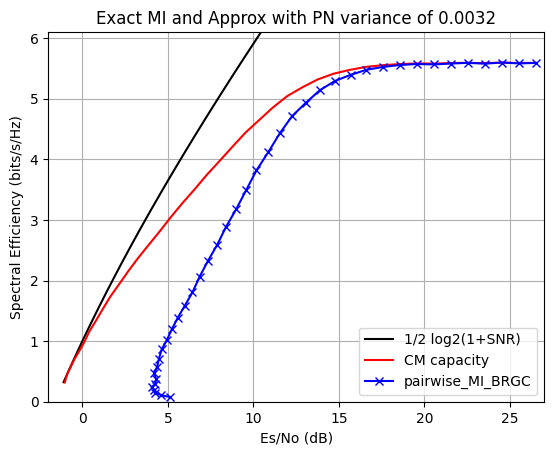

In [70]:
plt.figure()
plt.plot(EsNoVec-10*np.log10(shannoncap), shannoncap, '-', label='1/2 log2(1+SNR)', color='black') #-10*np.log10(shannoncap)
plt.plot(EsNoVec-10*np.log10(ccCap_exact), ccCap_exact, '-', label='CM capacity', color='red') #-10*np.log10(ccCap)
# plt.plot(EsNoVec-10*np.log10(pairwise_MI_BAD), pairwise_MI_BAD, '-x', label='pairwise_MI_BAD', color='green') #-10*np.log10(ccCap)
# plt.plot(EsNoVec-10*np.log10(pairwise_MI_Random2), pairwise_MI_Random2, '-x', label='pairwise_MI_Random2', color='orange') #-10*np.log10(ccCap)
plt.plot(EsNoVec-10*np.log10(pairwise_MI_BRGC), pairwise_MI_BRGC, '-x', label='pairwise_MI_BRGC', color='blue') #-10*np.log10(ccCap)
plt.grid(True)
plt.ylim([0, 6.1])
plt.xlim([-2, 27])
plt.title(f'Exact MI and Approx with PN variance of {pn_var}')
plt.xlabel('Es/No (dB)')
plt.ylabel('Spectral Efficiency (bits/s/Hz)')
plt.legend()

In [75]:

def binary_switching_algorithm(labels_init, px, results_exact_loaded, EsNoVec, max_iter=100, verbose=True):
    labels = labels_init.copy()
    M = len(labels)
    I_sum_current = compute_I_sum(labels, px, results_exact_loaded, EsNoVec)
    I_sum_initial = I_sum_current.copy()
    cost_current = np.mean(I_sum_current)  # or np.sum(), or integrate over SNR

    if verbose:
        print(f"BSA initialized: M={M}, initial cost={cost_current:.6f}")
        print(f"Initial labels: {labels}")

    improved = True
    iteration = 0

    while improved and iteration < max_iter:
        improved = False
        iteration += 1

        if verbose:
            print(f"\n=== Iteration {iteration} ===")

        # Compute per-symbol costs
        symbol_costs = np.zeros(M)
        label_bits = np.array([[int(c) for c in s] for s in labels], dtype=np.int32)

        for idx_a, idx_b in itertools.combinations(range(M), 2):
            if hamming_distance(label_bits[idx_a], label_bits[idx_b]) == 1:
                pair = (idx_a, idx_b)
                if pair in results_exact_loaded:
                    pair_w = px[idx_a] + px[idx_b]
                    arr = results_exact_loaded[pair]['ccCap']
                    contrib = pair_w * np.mean(arr)  # scalar cost
                    symbol_costs[idx_a] += contrib
                    symbol_costs[idx_b] += contrib

        # Sort by descending cost
        sorted_indices = np.argsort(-symbol_costs)

        if verbose:
            print(f"Symbol costs (sorted): {[(idx, symbol_costs[idx]) for idx in sorted_indices]}")

        for i in sorted_indices:
            best_swap = None
            best_delta = 0

            for j in range(M):
                if i == j:
                    continue

                # Try swap
                labels_test = labels.copy()
                labels_test[i], labels_test[j] = labels_test[j], labels_test[i]

                I_sum_test = compute_I_sum(labels_test, px, results_exact_loaded, EsNoVec)
                cost_test = np.mean(I_sum_test)
                delta = cost_test - cost_current

                if delta < best_delta:
                    best_delta = delta
                    best_swap = j

            if best_swap is not None:
                # Apply best swap for symbol i
                if verbose:
                    print(f"  Swap symbol {i} ('{labels[i]}') with symbol {best_swap} ('{labels[best_swap]}')")
                    print(f"    Cost before: {cost_current:.6f}, delta: {best_delta:.6f}")

                labels[i], labels[best_swap] = labels[best_swap], labels[i]
                cost_current += best_delta
                I_sum_current = compute_I_sum(labels, px, results_exact_loaded, EsNoVec)
                improved = True

                if verbose:
                    print(f"    Cost after: {cost_current:.6f}")
                    print(f"    New labels: {labels}")

                break  # Restart from highest-cost symbol

        if not improved and verbose:
            print("No improving swap found. BSA converged.")

    # Final summary
    if verbose:
        print("\n=== BSA Final Summary ===")
        print(f"Total iterations: {iteration}")
        print(f"Initial cost: {np.mean(I_sum_initial):.6f}")
        print(f"Final cost: {cost_current:.6f}")
        print(f"Improvement: {np.mean(I_sum_initial) - cost_current:.6f} ({100*(np.mean(I_sum_initial) - cost_current)/np.mean(I_sum_initial):.2f}%)")
        print(f"Final labels: {labels}")

    return labels, I_sum_current, I_sum_initial

In [76]:
labels_improved, I_sum_current, I_sum_initial = binary_switching_algorithm(labels, px, results_exact_loaded, EsNoVec, max_iter=100)

BSA initialized: M=64, initial cost=4.001432
Initial labels: ['000000', '000001', '000010', '000011', '000100', '000101', '000110', '000111', '001000', '001001', '001010', '001011', '001100', '001101', '001110', '001111', '010000', '010001', '010010', '010011', '010100', '010101', '010110', '010111', '011000', '011001', '011010', '011011', '011100', '011101', '011110', '011111', '100000', '100001', '100010', '100011', '100100', '100101', '100110', '100111', '101000', '101001', '101010', '101011', '101100', '101101', '101110', '101111', '110000', '110001', '110010', '110011', '110100', '110101', '110110', '110111', '111000', '111001', '111010', '111011', '111100', '111101', '111110', '111111']

=== Iteration 1 ===
Symbol costs (sorted): [(26, 0.22904832009226084), (54, 0.21884593088179827), (40, 0.21636196412146091), (24, 0.213576452806592), (52, 0.21316124498844147), (10, 0.21285894885659218), (42, 0.21056505478918552), (18, 0.2104126438498497), (50, 0.20915064495056868), (32, 0.208548

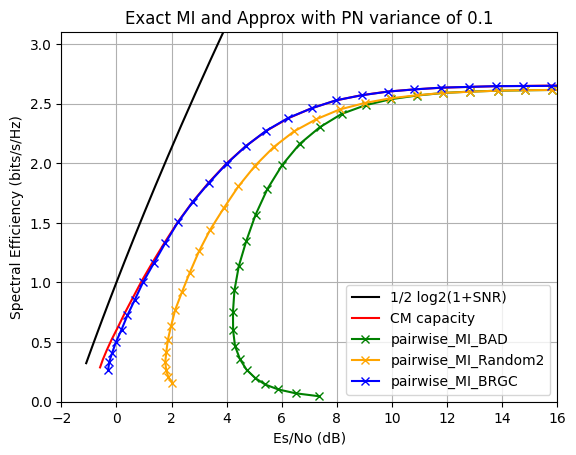

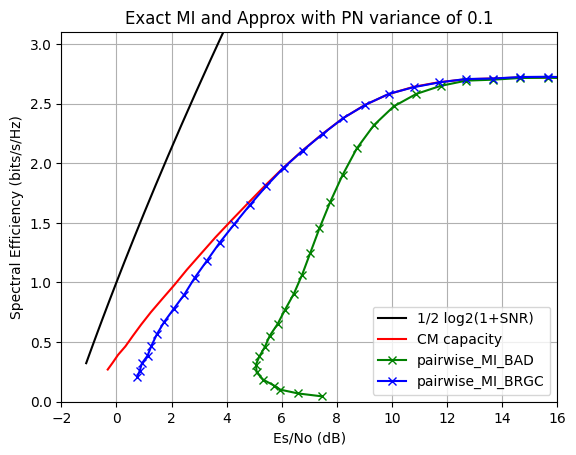

### BICM computation

In [59]:
@tf.function
def add_awgn_get_sigma(signal, ebno_db, bits_per_symbol):
    ebno_lin = tf.pow(10.0, ebno_db / 10.0)
    esno_lin = ebno_lin * tf.cast(bits_per_symbol, tf.float32)
    sigma2 = 1.0 / (2*esno_lin)
    sigma = tf.sqrt(sigma2)
    noise_r = tf.random.normal(tf.shape(signal), dtype=tf.float32)
    noise_i = tf.random.normal(tf.shape(signal), dtype=tf.float32)
    noise = tf.complex(noise_r, noise_i) * tf.cast(sigma, tf.complex64)
    return signal + noise, sigma2

@tf.function
def add_phase_noise_and_awgn_get_sigma(signal, ebno_db, bits_per_symbol, phase_noise_var):
    ebno_db = tf.cast(ebno_db, tf.float32)
    bits_per_symbol = tf.cast(bits_per_symbol, tf.float32)
    phase_noise_var = tf.cast(phase_noise_var, tf.float32)

    # Phase noise: phi ~ N(0, phase_noise_var)
    phi = tf.random.normal(tf.shape(signal), stddev=tf.sqrt(phase_noise_var), dtype=tf.float32)
    phase_rot = tf.complex(tf.cos(phi), tf.sin(phi))
    signal_pn = signal * phase_rot

    # AWGN from Eb/N0
    ebno_lin = tf.pow(10.0, ebno_db / 10.0)
    esno_lin = ebno_lin * bits_per_symbol
    sigma2 = 1.0 / (2.0 * esno_lin)
    sigma = tf.sqrt(sigma2)

    noise_r = tf.random.normal(tf.shape(signal), dtype=tf.float32)
    noise_i = tf.random.normal(tf.shape(signal), dtype=tf.float32)
    noise = tf.complex(noise_r, noise_i) * tf.cast(sigma, tf.complex64)

    return signal_pn + noise, sigma2


@tf.function
def bicm_batch_contribution(y, tx_bits, noise_var, pn_var, symbols, m, masks, condition, log_px, H_bits):
    
    y_exp = tf.expand_dims(y, axis=1)          # [B,1]
    s_exp = tf.expand_dims(symbols, axis=0)  # [1,M]
    
    if condition == 'awgn':
        # Real 1-D distance
        d2 = tf.square(y_exp - s_exp)           # [B,M]
        d2 = tf.math.real(d2)
        # metric proportional to log p(y|x), constants omitted because they cancel
        metric = -d2 / (2.0 * noise_var)        # [B,M]

    elif condition == 'exact':
        sym_exp = tf.broadcast_to(
        tf.expand_dims(symbols, 0),
        [tf.shape(y)[0], tf.shape(symbols)[0]]
        ) #[B,M]
    
        y_grid = tf.broadcast_to(y_exp, tf.shape(sym_exp))     # [B,M]
        
        metric = log_p_y_given_x_mc(
        y_grid,
        sym_exp,
        noise_var,
        pn_var,
        1024)

    elif condition == 'lowpn':
        metric = low_pn_approx_pdf(y_exp, s_exp, tf.sqrt(noise_var), tf.sqrt(pn_var))       # [B,M]

    elif condition == 'highsnr':
        metric = log_polar_approx_pdf(y_exp, s_exp, tf.sqrt(noise_var), tf.sqrt(pn_var))   # [B,M]
    
    # print(metric.dtype, log_px.dtype)
    metric_w = metric + log_px[None, :]   # weighted by symbol probabilities

    # full constellation log-sum-exp, shape [B]
    lse_all = tf.math.reduce_logsumexp(metric_w, axis=1)

    out = tf.TensorArray(dtype=tf.float32, size=m)
    for i in tf.range(m):
        b_i = tx_bits[:, i]  # [B], 0/1

        mask_i = tf.gather(masks[i], b_i)   # [B,M]

        neg_inf = tf.constant(-1e30, dtype=tf.float32)
        metric_masked = tf.where(mask_i > 0, metric_w, neg_inf)

        lse_subset = tf.math.reduce_logsumexp(metric_masked, axis=1)

        term = (lse_all - lse_subset) /tf.math.log(tf.constant(2.0, tf.float32))
        out = out.write(i, H_bits[i] - tf.reduce_mean(term))

    return out.stack() # tf.stack(out, axis=0)  # [m]

def estimate_bicm_capacity(esno_db_vec, n_samples, batch_size, symbols, lut_tf, m, masks, pn_var, condition, px, H_bits):
    bicmCap = np.zeros((m, len(esno_db_vec)), dtype=np.float32)
    num_batches = int(np.ceil(n_samples / batch_size))

    log_px = tf.cast(tf.math.log(px + 1e-30),tf.float32)
    px_tf = tf.constant(px, dtype=tf.float32)          # [M], sum(px)=1

    for n, esno_db in enumerate(esno_db_vec):
        ebno_db = esno_db - 10*np.log10(m)

        acc = np.zeros(m, dtype=np.float64)
        done = 0

        for _ in range(num_batches):
            B = min(batch_size, n_samples - done)
            if B <= 0:
                break

            # bits = tf.random.uniform((B, m), minval=0, maxval=2, dtype=tf.int32)
            # idx = bits_to_symbol_indices(bits, lut_tf, m)
            # x = tf.gather(symbols, idx)  # [B]
            idx = tf.random.categorical(tf.math.log([px_tf]), num_samples=B)[0]
            x = tf.gather(symbols, idx)
            bits = tf.gather(labels_bits, idx)   # if you still need bits for the per-bit 

            if condition == 'awgn':
                y, noise_var = add_awgn_get_sigma(x, tf.constant(ebno_db, tf.float32), m)
            else:
                y, noise_var = add_phase_noise_and_awgn_get_sigma(x, tf.constant(ebno_db, tf.float32), m, pn_var)   # [B]

            batch_bicm = bicm_batch_contribution(y, bits, noise_var, pn_var, symbols, m, masks, condition, log_px, H_bits)  # [m]

            acc += batch_bicm.numpy() * B
            done += B

        bicmCap[:, n] = acc / n_samples
        print(f"Es/No={esno_db:.1f} dB, BICM per bit = {bicmCap[:, n]}")

    return bicmCap

In [65]:
m

6

In [66]:
def normalize_symbols_for_px(symbols_np, px):
    avg_e = np.sum(px * (np.abs(symbols_np) ** 2))
    return symbols_np / np.sqrt(avg_e)

# labels = ['000','110','100','010','001','111','101','011'] # Gray like labeling
# q2, q1, q0 = 0.5, 0.5, 0.2
#
# bits = np.array([[int(c) for c in s] for s in labels], dtype=float)
# q = np.array([q2, q1, q0])
#
# px = np.prod(np.where(bits == 1, q, 1 - q), axis=1)
symbols_np = normalize_symbols_for_px(symbols_np, px)

labels_bits_np = np.array([[int(c) for c in s] for s in labels], dtype=np.int32)  # [16,4]

symbols = tf.constant(symbols_np, dtype=tf.complex64)          # [M]
labels_bits = tf.constant(labels_bits_np, dtype=tf.int32)    # [M, m]

M = symbols.shape[0]
m = labels_bits.shape[1]

p_bit = np.zeros((m, 2), dtype=np.float32)

for i in range(m):
    mask0 = (labels_bits[:, i] == 0)
    mask1 = (labels_bits[:, i] == 1)
    p_bit[i, 0] = np.sum(px[mask0])
    p_bit[i, 1] = np.sum(px[mask1])

H_p_bits = -np.sum(p_bit * np.log2(p_bit), axis=1)

# LUT: natural bit pattern -> symbol index, if needed for your mapping
label_vals = np.array([int("".join(map(str,row)), 2) for row in labels_bits_np], dtype=np.int32)
lut = np.empty(M, dtype=np.int32)
lut[label_vals] = np.arange(M, dtype=np.int32)
lut_tf = tf.constant(lut, dtype=tf.int32)


masks_np = np.zeros((m, 2, M), dtype=np.float32)
for i in range(m):
    for b in [0, 1]:
        masks_np[i, b, :] = (labels_bits_np[:, i] == b).astype(np.float32)
masks = tf.constant(masks_np, dtype=tf.float32)

pn_var = 0.0032
bicm_cap_bitwise_BRGC = estimate_bicm_capacity(EsNoVec, N_bicm, int(batch_size/100), symbols, lut_tf, m, masks, pn_var, 'exact', px, H_p_bits)

# estimate_bicm_capacity(esno_db_vec, n_samples, batch_size, symbols, lut_tf, m, masks, pn_var, condition, px, H_bits)

bicm_cap_BRGC = np.sum(bicm_cap_bitwise_BRGC,axis=0)
# bicm_cap_BRGC = np.maximum(np.sum(bicm_cap_bitwise_BRGC,axis=0) - sum_Hvi_BRGC + H_px,0.0)

Es/No=-6.0 dB, BICM per bit = [0.10324808 0.00893773 0.00145866 0.00077645 0.00439861 0.00288315]
Es/No=-5.0 dB, BICM per bit = [0.12909885 0.01332095 0.00162134 0.00091533 0.00438936 0.00090484]
Es/No=-4.0 dB, BICM per bit = [0.15416129 0.01892648 0.00223227 0.00118099 0.00626822 0.00745935]
Es/No=-3.0 dB, BICM per bit = [0.18933375 0.02860973 0.00273863 0.00149298 0.00789865 0.0072214 ]
Es/No=-2.0 dB, BICM per bit = [0.22384799 0.03984158 0.0040229  0.00180899 0.01040953 0.01750236]
Es/No=-1.0 dB, BICM per bit = [0.26239058 0.05413827 0.00610865 0.00230265 0.0125804  0.0264563 ]
Es/No=0.0 dB, BICM per bit = [0.30732432 0.07326595 0.00702488 0.00299869 0.01530295 0.02719036]
Es/No=1.0 dB, BICM per bit = [0.3509894  0.09699856 0.0098571  0.00381206 0.01625825 0.03884369]
Es/No=2.0 dB, BICM per bit = [0.3938458  0.12175186 0.01470555 0.00532105 0.02075859 0.05051314]
Es/No=3.0 dB, BICM per bit = [0.44045958 0.15356782 0.0233695  0.00680092 0.02488173 0.0626216 ]
Es/No=4.0 dB, BICM per b

In [60]:
def normalize_symbols_for_px(symbols_np, px):
    avg_e = np.sum(px * (np.abs(symbols_np) ** 2))
    return symbols_np / np.sqrt(avg_e)

labels = ['100','000','010','110','011','111','101','001']  # Much worse labeling
q2, q1, q0 = 0.5, 0.5, 0.2

bits = np.array([[int(c) for c in s] for s in labels], dtype=float)
q = np.array([q2, q1, q0])

px = np.prod(np.where(bits == 1, q, 1 - q), axis=1)
symbols_np = normalize_symbols_for_px(symbols_np, px)

labels_bits_np = np.array([[int(c) for c in s] for s in labels], dtype=np.int32)  # [16,4]

symbols = tf.constant(symbols_np, dtype=tf.complex64)          # [M]
labels_bits = tf.constant(labels_bits_np, dtype=tf.int32)    # [M, m]

M = symbols.shape[0]
m = labels_bits.shape[1]

p_bit = np.zeros((m, 2), dtype=np.float32)

for i in range(m):
    mask0 = (labels_bits[:, i] == 0)
    mask1 = (labels_bits[:, i] == 1)
    p_bit[i, 0] = np.sum(px[mask0])
    p_bit[i, 1] = np.sum(px[mask1])

H_p_bits = -np.sum(p_bit * np.log2(p_bit), axis=1)

# LUT: natural bit pattern -> symbol index, if needed for your mapping
label_vals = np.array([int("".join(map(str,row)), 2) for row in labels_bits_np], dtype=np.int32)
lut = np.empty(M, dtype=np.int32)
lut[label_vals] = np.arange(M, dtype=np.int32)
lut_tf = tf.constant(lut, dtype=tf.int32)


masks_np = np.zeros((m, 2, M), dtype=np.float32)
for i in range(m):
    for b in [0, 1]:
        masks_np[i, b, :] = (labels_bits_np[:, i] == b).astype(np.float32)
masks = tf.constant(masks_np, dtype=tf.float32)

pn_var = 0.1
bicm_cap_bitwise_BRGC = estimate_bicm_capacity(EsNoVec, N_bicm, int(batch_size/100), symbols, lut_tf, m, masks, pn_var, 'exact', px, H_p_bits)

# estimate_bicm_capacity(esno_db_vec, n_samples, batch_size, symbols, lut_tf, m, masks, pn_var, condition, px, H_bits)

bicm_cap_BAD = np.sum(bicm_cap_bitwise_BRGC,axis=0)

Es/No=-6.0 dB, BICM per bit = [0.01578077 0.00024558 0.01564373]
Es/No=-5.0 dB, BICM per bit = [0.02105702 0.00055688 0.02295237]
Es/No=-4.0 dB, BICM per bit = [0.02785011 0.00124317 0.03203042]
Es/No=-3.0 dB, BICM per bit = [0.03644199 0.00245871 0.04349966]
Es/No=-2.0 dB, BICM per bit = [0.04906154 0.0049951  0.06006395]
Es/No=-1.0 dB, BICM per bit = [0.06757504 0.00972558 0.08035104]
Es/No=0.0 dB, BICM per bit = [0.09279673 0.0180835  0.10884442]
Es/No=1.0 dB, BICM per bit = [0.12509395 0.03238359 0.13738911]
Es/No=2.0 dB, BICM per bit = [0.1702671  0.05612803 0.1764646 ]
Es/No=3.0 dB, BICM per bit = [0.22396357 0.09194264 0.21841435]
Es/No=4.0 dB, BICM per bit = [0.28996122 0.14221846 0.26622444]
Es/No=5.0 dB, BICM per bit = [0.36707622 0.21013351 0.32010812]
Es/No=6.0 dB, BICM per bit = [0.4515021  0.29429838 0.37791237]
Es/No=7.0 dB, BICM per bit = [0.5384738  0.38958183 0.43846774]
Es/No=8.0 dB, BICM per bit = [0.6273507  0.49030307 0.4993355 ]
Es/No=9.0 dB, BICM per bit = [0.70

In [67]:
def normalize_symbols_for_px(symbols_np, px):
    avg_e = np.sum(px * (np.abs(symbols_np) ** 2))
    return symbols_np / np.sqrt(avg_e)

# labels = ['100','000','010','110','011','111','101','001']  # Much worse labeling
labels = ['000','100','110','010','001','101','111','011']  # Random 2
q2, q1, q0 = 0.5, 0.5, 0.2

bits = np.array([[int(c) for c in s] for s in labels], dtype=float)
q = np.array([q2, q1, q0])

px = np.prod(np.where(bits == 1, q, 1 - q), axis=1)
symbols_np = normalize_symbols_for_px(symbols_np, px)

labels_bits_np = np.array([[int(c) for c in s] for s in labels], dtype=np.int32)  # [16,4]

symbols = tf.constant(symbols_np, dtype=tf.complex64)          # [M]
labels_bits = tf.constant(labels_bits_np, dtype=tf.int32)    # [M, m]

M = symbols.shape[0]
m = labels_bits.shape[1]

p_bit = np.zeros((m, 2), dtype=np.float32)

for i in range(m):
    mask0 = (labels_bits[:, i] == 0)
    mask1 = (labels_bits[:, i] == 1)
    p_bit[i, 0] = np.sum(px[mask0])
    p_bit[i, 1] = np.sum(px[mask1])

H_p_bits = -np.sum(p_bit * np.log2(p_bit), axis=1)

# LUT: natural bit pattern -> symbol index, if needed for your mapping
label_vals = np.array([int("".join(map(str,row)), 2) for row in labels_bits_np], dtype=np.int32)
lut = np.empty(M, dtype=np.int32)
lut[label_vals] = np.arange(M, dtype=np.int32)
lut_tf = tf.constant(lut, dtype=tf.int32)


masks_np = np.zeros((m, 2, M), dtype=np.float32)
for i in range(m):
    for b in [0, 1]:
        masks_np[i, b, :] = (labels_bits_np[:, i] == b).astype(np.float32)
masks = tf.constant(masks_np, dtype=tf.float32)

pn_var = 0.1
bicm_cap_bitwise_Random2 = estimate_bicm_capacity(EsNoVec, N_bicm, int(batch_size/100), symbols, lut_tf, m, masks, pn_var, 'exact', px, H_p_bits)

# estimate_bicm_capacity(esno_db_vec, n_samples, batch_size, symbols, lut_tf, m, masks, pn_var, condition, px, H_bits)

bicm_cap_Random2 = np.sum(bicm_cap_bitwise_Random2,axis=0)

Es/No=-6.0 dB, BICM per bit = [0.12896718 0.02048667 0.01551651]
Es/No=-5.0 dB, BICM per bit = [0.15683055 0.02934838 0.0237052 ]
Es/No=-4.0 dB, BICM per bit = [0.19084887 0.04205249 0.0319301 ]
Es/No=-3.0 dB, BICM per bit = [0.2280645  0.05966269 0.04419284]
Es/No=-2.0 dB, BICM per bit = [0.27175587 0.08228329 0.06052826]
Es/No=-1.0 dB, BICM per bit = [0.32107094 0.11266632 0.08066904]
Es/No=0.0 dB, BICM per bit = [0.3749934  0.14958416 0.10727359]
Es/No=1.0 dB, BICM per bit = [0.43281564 0.19487077 0.13770868]
Es/No=2.0 dB, BICM per bit = [0.4946409  0.2466829  0.17442462]
Es/No=3.0 dB, BICM per bit = [0.5539918  0.3056791  0.21923292]
Es/No=4.0 dB, BICM per bit = [0.614632   0.37219563 0.2667679 ]
Es/No=5.0 dB, BICM per bit = [0.67498314 0.44319516 0.32188419]
Es/No=6.0 dB, BICM per bit = [0.7299011  0.5170983  0.37914607]
Es/No=7.0 dB, BICM per bit = [0.7793452 0.5903301 0.4386834]
Es/No=8.0 dB, BICM per bit = [0.82200336 0.6588119  0.49896944]
Es/No=9.0 dB, BICM per bit = [0.85707

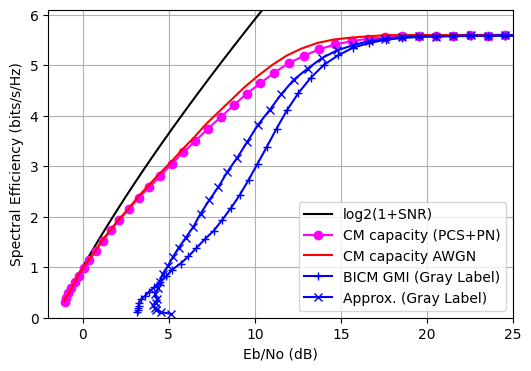

In [71]:
plt.figure(figsize=(6, 4))
plt.plot(EsNoVec-10*np.log10(shannoncap), shannoncap, '-', label='log2(1+SNR)', color='black') #-10*np.log10(shannoncap)
plt.plot(EsNoVec-10*np.log10(ccCap_exact), ccCap_exact, '-o', label='CM capacity (PCS+PN)', color='magenta') #-10*np.log10(ccCap)
plt.plot(EsNoVec-10*np.log10(ccCap_awgn), ccCap_awgn, '-', label='CM capacity AWGN', color='red') #-10*np.log10(ccCap)
# plt.plot(EsNoVec-10*np.log10(I_bi_NBC), I_bi_NBC, '--', label='I_bicm_NBC', color='green') #-10*np.log10(ccCap)
# plt.plot(EsNoVec-10*np.log10(I_bi_BRGC), I_bi_BRGC, '--', label='I_bicm_BRGC', color='blue') #-10*np.log10(ccCap)
# plt.plot(EsNoVec-10*np.log10(bicm_cap_Random2), bicm_cap_Random2, '-+', label='BICM GMI (Random Label 2)', color='orange') #-10*np.log10(ccCap)
# plt.plot(EsNoVec-10*np.log10(bicm_cap_BAD), bicm_cap_BAD, '-+', label='BICM GMI (Random Label 1)', color='green') #-10*np.log10(ccCap)
plt.plot(EsNoVec-10*np.log10(bicm_cap_BRGC), bicm_cap_BRGC, '-+', label='BICM GMI (Gray Label)', color='blue') #-10*np.log10(ccCap)
# plt.plot(EsNoVec-10*np.log10(pairwise_MI_Random2), pairwise_MI_Random2, '-x', label='Approx. (Random Label 2)', color='orange') #-10*np.log10(ccCap)
# plt.plot(EsNoVec-10*np.log10(pairwise_MI_BAD), pairwise_MI_BAD, '-x', label='Approx. (Random Label 1)', color='green') #-10*np.log10(ccCap)
plt.plot(EsNoVec-10*np.log10(pairwise_MI_BRGC), pairwise_MI_BRGC, '-x', label='Approx. (Gray Label)', color='blue') #-10*np.log10(ccCap)
# plt.plot(EsNoVec-10*np.log10(bicm_cap_NBC), bicm_cap_NBC, '-+', label='bicm_cap_NBC uniform', color='magenta') #-10*np.log10(ccCap)

plt.grid(True)
plt.ylim([0, 6.1])
plt.xlim([-2, 25])
plt.xlabel('Eb/No (dB)')
plt.ylabel('Spectral Efficiency (bits/s/Hz)')
plt.legend()
plt.savefig("bicm_gmi_approx_results.png", dpi=200, bbox_inches="tight")

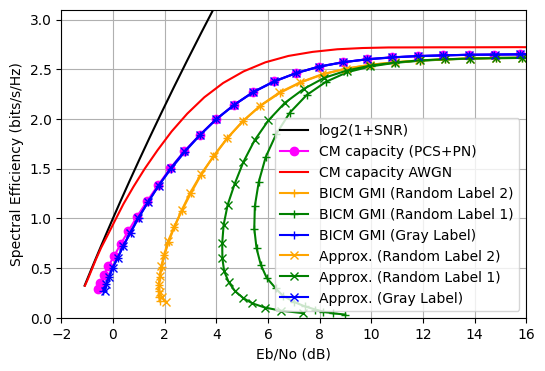

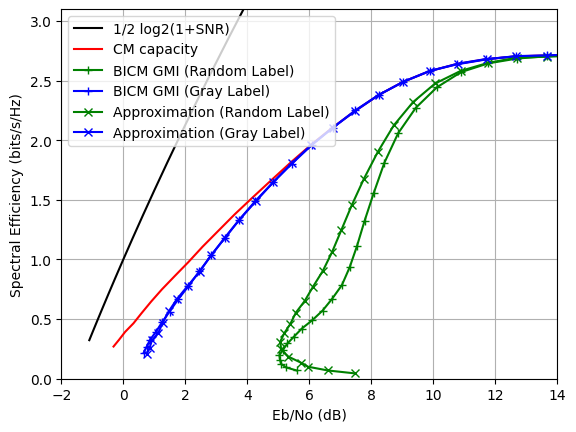